In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from matplotlib import gridspec
from method import improved_angle_simulation, get_range_shift
from method import plot_angle_simulation, plot_ranging_curve_green

sns.set_theme(style="ticks", font_scale=1.5)

In [2]:
# set waveform infos
FWHM = 1.5
mean_range = 500
beam_divergence = 0.001
sampling_time = 0.5*1e-9

# set angles for simulation
angles_simulation = np.arange(1, 81, 10) 

In [3]:
# run angle of incidence paper simulation - homotopie_term = 1 -> heavy-tailed curve
convolution_list_ht_0, time_intervals_ht_0, _ = improved_angle_simulation(angles_simulation, sampling_time, mean_range, beam_divergence, FWHM, homotopie_term=0)
convolution_list_ht_05, time_intervals_ht_05, _ = improved_angle_simulation(angles_simulation, sampling_time, mean_range, beam_divergence, FWHM, homotopie_term=0.5)
convolution_list_ht_1, time_intervals_ht_1, _ = improved_angle_simulation(angles_simulation, sampling_time, mean_range, beam_divergence, FWHM, homotopie_term=1)

In [4]:
range_list_ht_0, adjusted_range_list_ht_0 = get_range_shift(time_intervals_ht_0, sampling_time, convolution_list_ht_0, angles_simulation)
range_list_ht_05, adjusted_range_list_ht_05 = get_range_shift(time_intervals_ht_05, sampling_time, convolution_list_ht_05, angles_simulation)
range_list_ht_1, adjusted_range_list_ht_1 = get_range_shift(time_intervals_ht_1, sampling_time, convolution_list_ht_1, angles_simulation)

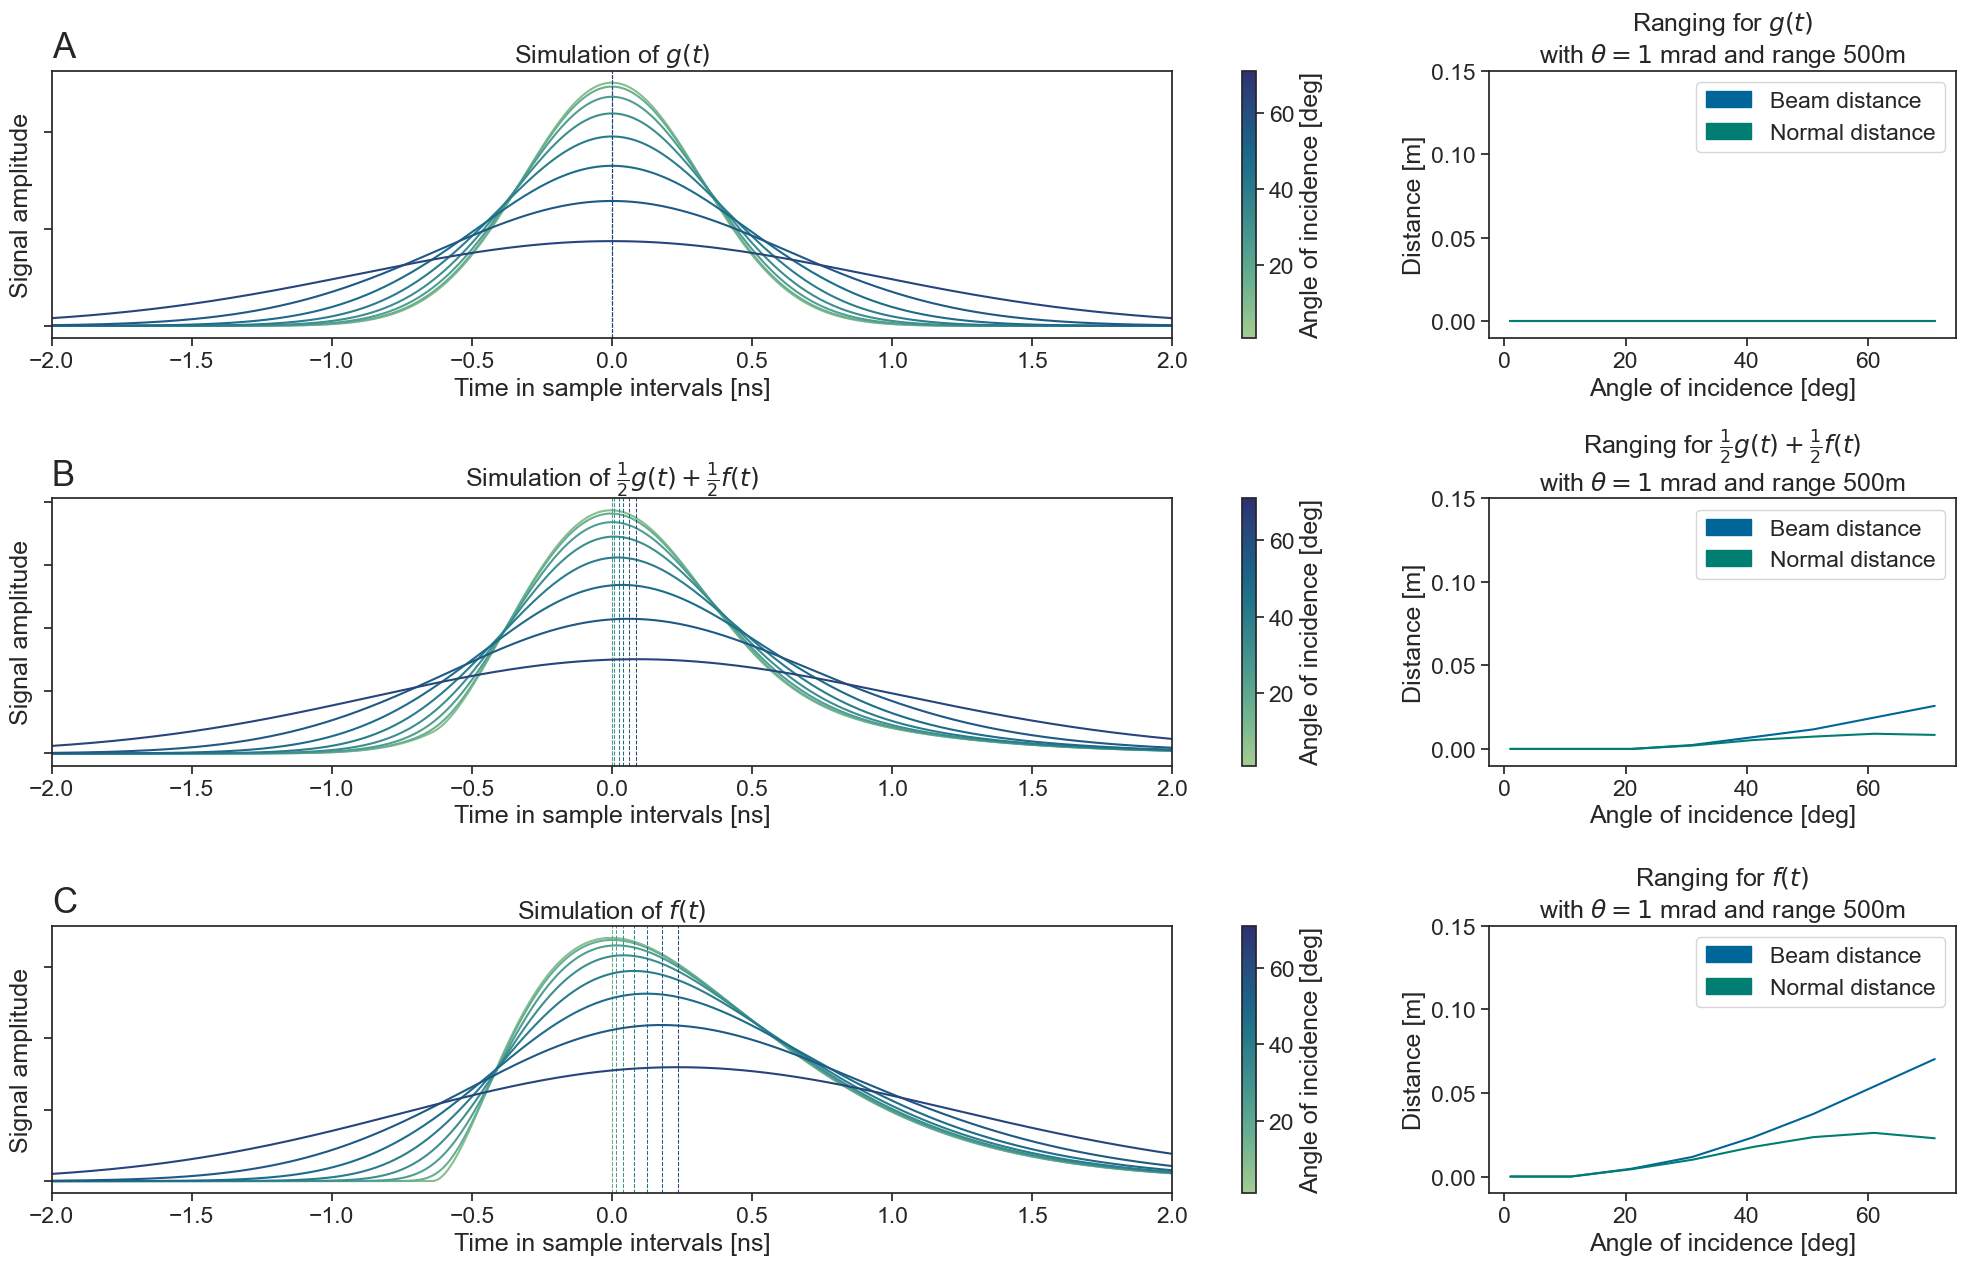

In [6]:
fig = plt.figure(figsize=(20, 13))
gs = gridspec.GridSpec(3, 2, width_ratios=[3, 1]) 

ax = plt.subplot(gs[0])
plot_angle_simulation(time_intervals_ht_0, sampling_time, convolution_list_ht_0, angles_simulation, "$g(t)$", "A")

plt.subplot(gs[1])
plot_ranging_curve_green(angles_simulation, range_list_ht_0, adjusted_range_list_ht_0, "$g(t)$\nwith $\\theta=1$ mrad and range 500m")

ax = plt.subplot(gs[2])
plot_angle_simulation(time_intervals_ht_05, sampling_time, convolution_list_ht_05, angles_simulation, "$\\frac{1}{2} g(t) +\\frac{1}{2} f(t)$", "B")

plt.subplot(gs[3])
plot_ranging_curve_green(angles_simulation, range_list_ht_05, adjusted_range_list_ht_05, "$\\frac{1}{2} g(t) +\\frac{1}{2} f(t)$\nwith $\\theta=1$ mrad and range 500m")

ax = plt.subplot(gs[4])
plot_angle_simulation(time_intervals_ht_1, sampling_time, convolution_list_ht_1, angles_simulation,  "$f(t)$", "C")

plt.subplot(gs[5])
plot_ranging_curve_green(angles_simulation, range_list_ht_1, adjusted_range_list_ht_1, "$f(t)$\nwith $\\theta=1$ mrad and range 500m")

plt.tight_layout()